## 02: MLP - Classification
## 03: MLP - Regression

In [1]:
!pip install praat-parselmouth

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 67.1 MB/s eta 0:00:00


In [2]:
!pip install pyworld

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.0/261.0 kB 17.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyworld: filename=pyworld-0.3.5-cp312-cp312-linux_x86_64.whl size=943577 sha256=7fda6e410ebb578dc6294a8403858b4dce7ed756a4feab29224574c3b3b1ee29
  Stored in directory: /root/.cache/pip/wheels/be/ac/58/c6a1791ec6d17f3a99b6ccdec92b472f560cb5c564b83dd77e
Successfully built pyworld


In [3]:
import zipfile
import pandas as pd
import json
import os
import librosa
import soundfile
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import librosa
import pyworld as pw
import parselmouth
import os
import json
import pandas as pd
import os
from tqdm import tqdm

In [ ]:
zip_path = '/content/drive/MyDrive/SingMOS/SingMOS-Pro.zip'
extract_to = '/content/SingMOS/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

In [ ]:
# T ow orkspace folder for faster read
audio_path = "/content/SingMOS/SingMOS-Pro/wav"
score_path = "/content/drive/MyDrive/SingMOS/SingMOS-Pro/info/score.json"

In [ ]:
with open(score_path, "r") as f:
  data = json.load(f)

utterances = data["utterance"]

rows = []
for utt_id, utt_data in utterances.items():
  row = {
      "utterance_id": utt_id,
      "sys_id": utt_data.get("sys_id"),
      "wav": utt_data.get("wav"),
      "mos": utt_data.get("score", {}).get("mos")
  }
  rows.append(row)


df = pd.DataFrame(rows)

df.head()

,utterance_id,sys_id,wav,mos
0,sys0001-utt0001,sys0001,wav/sys0001-utt0001.wav,4.0
1,sys0001-utt0002,sys0001,wav/sys0001-utt0002.wav,4.6
2,sys0001-utt0003,sys0001,wav/sys0001-utt0003.wav,3.4
3,sys0001-utt0004,sys0001,wav/sys0001-utt0004.wav,4.2
4,sys0001-utt0005,sys0001,wav/sys0001-utt0005.wav,4.2


In [ ]:
SAMPLING_RATE = 16_000

wav_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(audio_path)
    for f in files
    if f.lower().endswith(".wav")
]

print(f"Found {len(wav_files)} wav files.")


def load_audio(path, sr=SAMPLING_RATE):
    try:
        y, sr = librosa.load(path, sr=sr)
        return y, sr, len(y) / sr
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None, None, None

records = []
for wav in tqdm(wav_files, desc="Loading audio files", unit="file"):
    y, sr, dur = load_audio(wav)
    if y is not None:
        records.append({
            "wav_path": wav,
            "audio": y,
            "sr": sr,
            "duration_sec": dur
        })


df_audio = pd.DataFrame(records)
print(df_audio.head())

Found 7981 wav files.


Loading audio files: 100%|██████████| 7981/7981 [00:27<00:00, 295.12file/s]

                                            wav_path  \
0  /content/SingMOS/SingMOS-Pro/wav/sys0036-utt34...   
1  /content/SingMOS/SingMOS-Pro/wav/sys0057-utt43...   
2  /content/SingMOS/SingMOS-Pro/wav/sys0065-utt47...   
3  /content/SingMOS/SingMOS-Pro/wav/sys0034-utt31...   
4  /content/SingMOS/SingMOS-Pro/wav/sys0133-utt76...   

                                               audio     sr  duration_sec  
0  [0.021759033, 0.008026123, 0.005126953, 0.0032...  16000       5.93750  
1  [0.006652832, 0.0022583008, 0.00061035156, 0.0...  16000       4.37500  
2  [-0.019414425, 0.011650449, -0.009551597, -0.0...  16000       6.03725  
3  [-0.00036621094, -0.00039672852, -0.0009155273...  16000       4.99000  
4  [0.0016848445, -0.0014360249, -0.020301722, -0...  16000       6.27200  


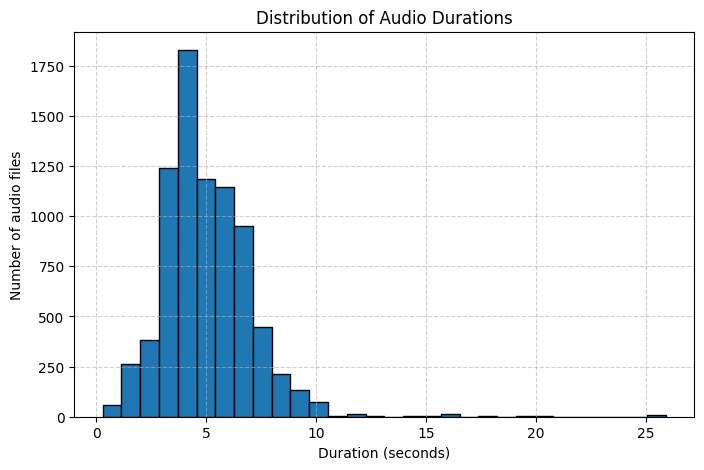

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df_audio["duration_sec"], bins=30, edgecolor='black')
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of audio files")
plt.title("Distribution of Audio Durations")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

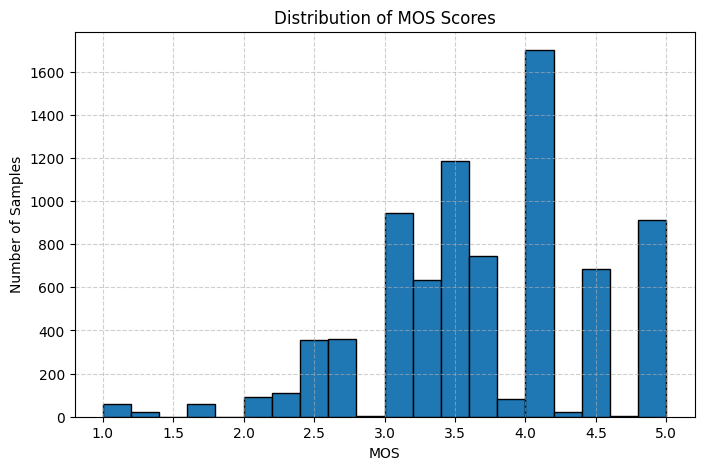

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df["mos"], bins=20, edgecolor="black")
plt.xlabel("MOS")
plt.ylabel("Number of Samples")
plt.title("Distribution of MOS Scores")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [ ]:
def mos_category_strict(mos):
    if mos < 3.0:
        return "Poor"
    elif mos < 3.75:
        return "Mediocre"
    elif mos < 4.5:
        return "Good"
    else:
        return "Excellent"

df["mos_category"] = df["mos"].apply(mos_category_strict)
print(df["mos_category"].value_counts())


mos_category
Mediocre     2855
Good         2823
Excellent    1240
Poor         1063
Name: count, dtype: int64


In [ ]:
def extract_acoustic_timeseries(y, sr, wav_path, frame_length=1024, hop_length=512):
    # frame_length: Samples in an analysis window
    # hop_length: Samples between frames

    # Metadata
    filename = os.path.basename(wav_path)
    duration_sec = len(y) / sr

    # Short-time features
    times = librosa.frames_to_time(np.arange(len(y)//hop_length), sr=sr, hop_length=hop_length)

    rms = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)[0]
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=frame_length, hop_length=hop_length)[0]
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr, n_fft=frame_length, hop_length=hop_length)[0]
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, n_fft=frame_length, hop_length=hop_length)[0]
    flux = librosa.onset.onset_strength(y=y, sr=sr, hop_length=hop_length)

    # Pitch (f0) extraction
    # lowest pitch: 60 Hz
    # Highest pitch: 1200 Hz
    _f0, t = pw.harvest(y.astype(np.float64), sr, f0_floor=60.0, f0_ceil=1200.0, frame_period=hop_length/sr*1000)
    f0 = pw.stonemask(y.astype(np.float64), _f0, t, sr)

    # interpolate f0 to librosa time grid
    f0_interp = np.interp(times, t, f0, left=np.nan, right=np.nan)
    f0_interp = pd.Series(f0_interp).rolling(window=5, min_periods=1, center=True).median().to_numpy()
    # smooth f0 interpolation

    # compute mean f0 (Voiced frames only)
    voiced = f0_interp[f0_interp > 0]
    f0_mean = np.nanmean(voiced) if len(voiced) > 0 else np.nan

    # Compute offset from mean (deep and high pitched voices have the same "advantage")
    f0_offset = f0_interp - f0_mean if np.isfinite(f0_mean) else np.zeros_like(f0_interp)

    # Voice quality (frame-level)
    snd = parselmouth.Sound(y, sr)
    point_process = parselmouth.praat.call(snd, "To PointProcess (periodic, cc)", 75, 600)

    # Estimate global HNR/jitter/shimmer per segment
    hnr_obj = parselmouth.praat.call(snd, "To Harmonicity (cc)",
                                     0.01, # time step
                                     75, # min pitch
                                     0.1, # silenc threshold
                                     1.0 # periodicity threshold
                                     )
    hnr_values = hnr_obj.values[0]
    hnr_time = np.linspace(0, len(y)/sr, len(hnr_values))
    hnr_interp = np.interp(times, hnr_time, hnr_values, left=np.nan, right=np.nan)

    # Shimmer and jitter don't work for some reason
    try:
      jitter = parselmouth.praat.call([snd, point_process], "Get jitter (local)",
                                      0, # start time
                                      0, # end time (use whole)
                                      75, # min pitch
                                      600, # max pitch
                                      1.3 # reject outlier pulses
                                      )
    except:
      jitter = np.nan

    try:
      # same params as jitter
      shimmer = parselmouth.praat.call([snd, point_process], "Get shimmer (local)", 0, 0, 75, 600, 1.3)
    except:
      shimmer = np.nan

    jitter_series = np.repeat(jitter, len(times))
    shimmer_series = np.repeat(shimmer, len(times))

    # Create df
    df = pd.DataFrame({
        "filename": filename,
        "wav_path": wav_path,
        "time_sec": times,
        "rms": rms[:len(times)],
        "centroid": centroid[:len(times)],
        "bandwidth": bandwidth[:len(times)],
        "rolloff": rolloff[:len(times)],
        "flux": flux[:len(times)],
        "f0": f0_interp[:len(times)],
        "f0_mean": np.repeat(f0_mean, len(times)),
        "f0_offset": f0_offset[:len(times)],
        "hnr": hnr_interp[:len(times)],
        "jitter": jitter_series[:len(times)],
        "shimmer": shimmer_series[:len(times)],
        "duration_sec": np.repeat(duration_sec, len(times))
    })

    return df

In [ ]:
def aggregate_acoustic_features(df_ts, feature_cols=None, prefix=""):
    # wav -> Aggregated acoustic features

    if feature_cols is None:
        feature_cols = df_ts.select_dtypes(include=[np.number]).columns.tolist()

    # Agg functions
    agg_funcs = {
        "mean": np.nanmean,
        "std": np.nanstd,
        "median": np.nanmedian,
        "min": np.nanmin,
        "max": np.nanmax,
        "skew": pd.Series.skew,
        "kurtosis": pd.Series.kurtosis,
    }

    agg_data = {}

    for col in feature_cols:
        series = pd.Series(df_ts[col]).replace([np.inf, -np.inf], np.nan).dropna()
        if len(series) == 0:
            # Fill if silent or failed extraction
            for stat_name in agg_funcs.keys():
                agg_data[f"{prefix}{col}_{stat_name}"] = np.nan
            continue
        for stat_name, func in agg_funcs.items():
            try:
                agg_data[f"{prefix}{col}_{stat_name}"] = func(series)
            except Exception:
                agg_data[f"{prefix}{col}_{stat_name}"] = np.nan

        # Percentiles
        for p in [25, 75]:
            agg_data[f"{prefix}{col}_p{p}"] = np.nanpercentile(series, p)

    return pd.DataFrame([agg_data])


In [ ]:
all_features = []

for _, row in df_audio.iterrows():
    y, sr, path = row["audio"], row["sr"], row["wav_path"]
    df_ts = extract_acoustic_timeseries(y, sr, path)
    df_agg = aggregate_acoustic_features(df_ts)
    df_agg["filename"] = os.path.basename(path)
    all_features.append(df_agg)

df_features = pd.concat(all_features, ignore_index=True)

# 2 hours later...

In [ ]:
# Save
df_features.to_csv("/content/drive/MyDrive/MOS-acoustic/features.csv", index=False)

## Read + process data

In [4]:
features_path = "/content/drive/MyDrive/MOS-acoustic/features.csv"
scores_path = "/content/drive/MyDrive/SingMOS/SingMOS-Pro/info/score.json"



In [5]:
audio_features = pd.read_csv(features_path)
audio_features.head()

,time_sec_mean,time_sec_std,time_sec_median,time_sec_min,time_sec_max,time_sec_skew,time_sec_kurtosis,time_sec_p25,time_sec_p75,rms_mean,...,duration_sec_mean,duration_sec_std,duration_sec_median,duration_sec_min,duration_sec_max,duration_sec_skew,duration_sec_kurtosis,duration_sec_p25,duration_sec_p75,filename
0,2.000,1.163901,2.000,0.0,4.000,-6.334723e-17,-1.2,1.000,3.000,0.072252,...,4.061875,0.000000e+00,4.061875,4.061875,4.061875,0.0,0.0,4.061875,4.061875,sys0001-utt0001.wav
1,3.408,1.976826,3.408,0.0,6.816,9.695721e-16,-1.2,1.704,5.112,0.039835,...,6.871062,1.776357e-15,6.871062,6.871062,6.871062,0.0,0.0,6.871062,6.871062,sys0001-utt0002.wav
2,1.360,0.794380,1.360,0.0,2.720,-3.355180e-16,-1.2,0.680,2.040,0.057899,...,2.772437,8.881784e-16,2.772438,2.772438,2.772438,0.0,0.0,2.772438,2.772438,sys0001-utt0003.wav
3,1.600,0.932952,1.600,0.0,3.200,-9.783990e-16,-1.2,0.800,2.400,0.051241,...,3.257750,0.000000e+00,3.257750,3.257750,3.257750,0.0,0.0,3.257750,3.257750,sys0001-utt0004.wav
4,3.536,2.050727,3.536,0.0,7.072,0.000000e+00,-1.2,1.768,5.304,0.018278,...,7.130937,8.881784e-16,7.130937,7.130937,7.130937,0.0,0.0,7.130937,7.130937,sys0001-utt0005.wav


In [6]:
with open(scores_path, "r") as f:
  data = json.load(f)

utterances =  data["utterance"]

rows = []
for utt_id, utt_data in utterances.items():
  row = {
      "utterance_id": utt_id,
      "sys_id": utt_data.get("sys_id"),
      "wav": utt_data.get("wav"),
      "mos": utt_data.get("score", {}).get("mos")
  }
  rows.append(row)

df = pd.DataFrame(rows)
df.head()

,utterance_id,sys_id,wav,mos
0,sys0001-utt0001,sys0001,wav/sys0001-utt0001.wav,4.0
1,sys0001-utt0002,sys0001,wav/sys0001-utt0002.wav,4.6
2,sys0001-utt0003,sys0001,wav/sys0001-utt0003.wav,3.4
3,sys0001-utt0004,sys0001,wav/sys0001-utt0004.wav,4.2
4,sys0001-utt0005,sys0001,wav/sys0001-utt0005.wav,4.2


In [7]:
audio_features.columns.to_list()

['time_sec_mean',
 'time_sec_std',
 'time_sec_median',
 'time_sec_min',
 'time_sec_max',
 'time_sec_skew',
 'time_sec_kurtosis',
 'time_sec_p25',
 'time_sec_p75',
 'rms_mean',
 'rms_std',
 'rms_median',
 'rms_min',
 'rms_max',
 'rms_skew',
 'rms_kurtosis',
 'rms_p25',
 'rms_p75',
 'centroid_mean',
 'centroid_std',
 'centroid_median',
 'centroid_min',
 'centroid_max',
 'centroid_skew',
 'centroid_kurtosis',
 'centroid_p25',
 'centroid_p75',
 'bandwidth_mean',
 'bandwidth_std',
 'bandwidth_median',
 'bandwidth_min',
 'bandwidth_max',
 'bandwidth_skew',
 'bandwidth_kurtosis',
 'bandwidth_p25',
 'bandwidth_p75',
 'rolloff_mean',
 'rolloff_std',
 'rolloff_median',
 'rolloff_min',
 'rolloff_max',
 'rolloff_skew',
 'rolloff_kurtosis',
 'rolloff_p25',
 'rolloff_p75',
 'flux_mean',
 'flux_std',
 'flux_median',
 'flux_min',
 'flux_max',
 'flux_skew',
 'flux_kurtosis',
 'flux_p25',
 'flux_p75',
 'f0_mean',
 'f0_std',
 'f0_median',
 'f0_min',
 'f0_max',
 'f0_skew',
 'f0_kurtosis',
 'f0_p25',
 'f0_

In [8]:
# Shimmer, Jitter: Null everywhere -> Drop
# time_sec, duration_sec: Irrelevant data

audio_features.drop([col for col in audio_features.columns if "shimmer" in col], inplace=True, axis=1)
audio_features.drop([col for col in audio_features.columns if "jitter" in col], inplace=True, axis=1)
audio_features.drop([col for col in audio_features.columns if "time_sec" in col], inplace=True, axis=1)
audio_features.drop([col for col in audio_features.columns if "duration_sec" in col], inplace=True, axis=1)

In [9]:
audio_features.head()

,rms_mean,rms_std,rms_median,rms_min,rms_max,rms_skew,rms_kurtosis,rms_p25,rms_p75,centroid_mean,...,hnr_mean,hnr_std,hnr_median,hnr_min,hnr_max,hnr_skew,hnr_kurtosis,hnr_p25,hnr_p75,filename
0,0.072252,0.038856,0.072478,0.001352,0.151233,-0.034134,-0.767019,0.047039,0.102916,2021.089075,...,-7.119562,72.862404,22.748289,-200.0,32.551897,-2.198242,3.073222,14.643348,26.492778,sys0001-utt0001.wav
1,0.039835,0.020939,0.039112,0.000015,0.113200,0.255079,0.356579,0.028647,0.051957,1916.451822,...,-20.286808,85.290951,20.883888,-200.0,35.074652,-1.592006,0.621188,1.719615,25.894600,sys0001-utt0002.wav
2,0.057899,0.036136,0.055233,0.000378,0.155549,0.369084,-0.267861,0.030228,0.081504,2435.085131,...,-20.001704,83.327354,20.087031,-200.0,30.778629,-1.636341,0.769389,4.098366,23.940861,sys0001-utt0003.wav
3,0.051241,0.023885,0.047418,0.003876,0.136289,0.884045,1.861116,0.038811,0.063741,1716.877921,...,-9.113975,72.855943,18.822082,-200.0,31.432771,-2.161567,2.899471,11.782742,24.029632,sys0001-utt0004.wav
4,0.018278,0.012395,0.018631,0.000085,0.049374,0.100403,-0.893602,0.007934,0.027568,1449.847592,...,-29.208034,95.380895,24.693313,-200.0,39.688844,-1.192692,-0.529086,-3.106494,29.170019,sys0001-utt0005.wav


In [10]:
audio_features.columns.to_list()

['rms_mean',
 'rms_std',
 'rms_median',
 'rms_min',
 'rms_max',
 'rms_skew',
 'rms_kurtosis',
 'rms_p25',
 'rms_p75',
 'centroid_mean',
 'centroid_std',
 'centroid_median',
 'centroid_min',
 'centroid_max',
 'centroid_skew',
 'centroid_kurtosis',
 'centroid_p25',
 'centroid_p75',
 'bandwidth_mean',
 'bandwidth_std',
 'bandwidth_median',
 'bandwidth_min',
 'bandwidth_max',
 'bandwidth_skew',
 'bandwidth_kurtosis',
 'bandwidth_p25',
 'bandwidth_p75',
 'rolloff_mean',
 'rolloff_std',
 'rolloff_median',
 'rolloff_min',
 'rolloff_max',
 'rolloff_skew',
 'rolloff_kurtosis',
 'rolloff_p25',
 'rolloff_p75',
 'flux_mean',
 'flux_std',
 'flux_median',
 'flux_min',
 'flux_max',
 'flux_skew',
 'flux_kurtosis',
 'flux_p25',
 'flux_p75',
 'f0_mean',
 'f0_std',
 'f0_median',
 'f0_min',
 'f0_max',
 'f0_skew',
 'f0_kurtosis',
 'f0_p25',
 'f0_p75',
 'f0_mean_mean',
 'f0_mean_std',
 'f0_mean_median',
 'f0_mean_min',
 'f0_mean_max',
 'f0_mean_skew',
 'f0_mean_kurtosis',
 'f0_mean_p25',
 'f0_mean_p75',
 'f

In [11]:
# Combine dataframes
scores = df
scores["wav"] = scores["wav"].str.replace("wav/", "", regex=False)
scores.head()

,utterance_id,sys_id,wav,mos
0,sys0001-utt0001,sys0001,sys0001-utt0001.wav,4.0
1,sys0001-utt0002,sys0001,sys0001-utt0002.wav,4.6
2,sys0001-utt0003,sys0001,sys0001-utt0003.wav,3.4
3,sys0001-utt0004,sys0001,sys0001-utt0004.wav,4.2
4,sys0001-utt0005,sys0001,sys0001-utt0005.wav,4.2


In [12]:
# Bucketing to improve MOS distribution
def mos_category(mos):
  if mos < 3.0:
    return "Poor"
  if mos < 3.75:
    return "Mediocre"
  if mos < 4.5:
    return "Good"
  return "Excellent"

scores["mos_category"] = scores["mos"].apply(mos_category)
scores.head()

,utterance_id,sys_id,wav,mos,mos_category
0,sys0001-utt0001,sys0001,sys0001-utt0001.wav,4.0,Good
1,sys0001-utt0002,sys0001,sys0001-utt0002.wav,4.6,Excellent
2,sys0001-utt0003,sys0001,sys0001-utt0003.wav,3.4,Mediocre
3,sys0001-utt0004,sys0001,sys0001-utt0004.wav,4.2,Good
4,sys0001-utt0005,sys0001,sys0001-utt0005.wav,4.2,Good


In [13]:
scores = scores[["wav", "mos_category", "mos"]]
scores.head()

,wav,mos_category,mos
0,sys0001-utt0001.wav,Good,4.0
1,sys0001-utt0002.wav,Excellent,4.6
2,sys0001-utt0003.wav,Mediocre,3.4
3,sys0001-utt0004.wav,Good,4.2
4,sys0001-utt0005.wav,Good,4.2


In [14]:
# Join scores
df = pd.merge(audio_features, scores, left_on="filename", right_on="wav", how="inner")
df.drop(["wav", "filename"], inplace=True, axis=1)
df.head()

,rms_mean,rms_std,rms_median,rms_min,rms_max,rms_skew,rms_kurtosis,rms_p25,rms_p75,centroid_mean,...,hnr_std,hnr_median,hnr_min,hnr_max,hnr_skew,hnr_kurtosis,hnr_p25,hnr_p75,mos_category,mos
0,0.072252,0.038856,0.072478,0.001352,0.151233,-0.034134,-0.767019,0.047039,0.102916,2021.089075,...,72.862404,22.748289,-200.0,32.551897,-2.198242,3.073222,14.643348,26.492778,Good,4.0
1,0.039835,0.020939,0.039112,0.000015,0.113200,0.255079,0.356579,0.028647,0.051957,1916.451822,...,85.290951,20.883888,-200.0,35.074652,-1.592006,0.621188,1.719615,25.894600,Excellent,4.6
2,0.057899,0.036136,0.055233,0.000378,0.155549,0.369084,-0.267861,0.030228,0.081504,2435.085131,...,83.327354,20.087031,-200.0,30.778629,-1.636341,0.769389,4.098366,23.940861,Mediocre,3.4
3,0.051241,0.023885,0.047418,0.003876,0.136289,0.884045,1.861116,0.038811,0.063741,1716.877921,...,72.855943,18.822082,-200.0,31.432771,-2.161567,2.899471,11.782742,24.029632,Good,4.2
4,0.018278,0.012395,0.018631,0.000085,0.049374,0.100403,-0.893602,0.007934,0.027568,1449.847592,...,95.380895,24.693313,-200.0,39.688844,-1.192692,-0.529086,-3.106494,29.170019,Good,4.2


In [15]:
# Separate features
X = df.drop(["mos_category", "mos"], axis=1)
y = df["mos_category"]

In [16]:
# feature selection
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LassoCV
from tensorflow.keras.utils import to_categorical
import numpy as np
import pandas as pd

scaler = StandardScaler()
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
X_scaled = scaler.fit_transform(X)

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
y_onehot = to_categorical(y_encoded)
y_numeric = np.argmax(y_onehot, axis=1)

lasso = LassoCV(cv=5, random_state=42, max_iter=10_000)
lasso.fit(X_scaled, y_numeric)

selected_mask = lasso.coef_ != 0
X_selected = X_scaled[:, selected_mask]

print(f"Selected features: {selected_mask.sum()} / {X.shape[1]} features")

Selected features: 47 / 81 features


## Build model - Classification

In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input, ReLU, Activation, Lambda
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import regularizers

def build_mlp_classifier_1024_old(input_dim, num_classes=4):
  model = Sequential[(
      Dense(1024, activation="relu", input_shape=(input_dim,)),
      BatchNormalization(),
      Dropout(0.5),

      Dense(512, activation="relu"),
      BatchNormalization(),
      Dropout(0.5),

      Dense(256, activation="relu"),
      BatchNormalization(),
      Dropout(0.5),

      Dense(128, activation="relu"),
      BatchNormalization(),
      Dropout(0.5),

      Dense(64, activation="relu"),
      BatchNormalization(),
      Dropout(0.5),

      Dense(num_classes, activation="softmax")
  )]

  model.compile(
      optimizer=Adam(learning_rate=0.001),
      loss="categorical_crossentropy",
      metrics=["accuracy"]
  )

  return model


def build_mlp_classifier_1024(input_dim, num_classes=4):
    l2_lambda = 1e-4

    model = Sequential([

        Dense(1024, kernel_regularizer=regularizers.l2(l2_lambda), input_shape=(input_dim,)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.3),

        Dense(512,kernel_regularizer=regularizers.l2(l2_lambda)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.3),

        Dense(256, kernel_regularizer=regularizers.l2(l2_lambda)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.3),

        Dense(128, kernel_regularizer=regularizers.l2(l2_lambda)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.3),

        Dense(64, kernel_regularizer=regularizers.l2(l2_lambda)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.5),

        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def build_mlp_classifier_512(input_dim, num_classes=4):

    model = Sequential([

        Dense(512, input_shape=(input_dim,)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.5),

        Dense(256),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.5),

        Dense(128),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.5),

        Dense(64),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.5),

        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


def build_mlp_classifier_256(input_dim, num_classes=4):

    model = Sequential([

        Dense(256, input_shape=(input_dim,)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.5),

        Dense(128),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.5),

        Dense(64),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.5),

        Dense(num_classes, activation="softmax")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

## Train model

In [18]:
model_classifier_1024 = build_mlp_classifier_1024(X_selected.shape[1])
model_classifier_512 = build_mlp_classifier_512(X_selected.shape[1])
model_classifier_256 = build_mlp_classifier_256(X_selected.shape[1])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
model_classifier_1024.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1024)           │        49,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 754,628 (2.88 MB)

 Trainable params: 750,660 (2.86 MB)

 Non-trainable params: 3,968 (15.50 KB)

In [20]:
model_classifier_512.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 512)            │        24,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 201,156 (785.77 KB)

 Trainable params: 199,236 (778.27 KB)

 Non-trainable params: 1,920 (7.50 KB)

In [21]:
model_classifier_256.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 256)            │        12,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,492 (216.77 KB)

 Trainable params: 54,596 (213.27 KB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_selected, y_onehot, test_size=0.3, random_state=42, stratify=y_onehot
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=5,
    min_lr=1e-5
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)


In [ ]:
history_c_1024 = model_classifier_1024.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[reduce_lr, early_stopping]
)

Epoch 1/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4953 - loss: 1.1972 - val_accuracy: 0.5572 - val_loss: 1.0842 - learning_rate: 1.0000e-05
Epoch 2/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5094 - loss: 1.1872 - val_accuracy: 0.5631 - val_loss: 1.0825 - learning_rate: 1.0000e-05
Epoch 3/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4948 - loss: 1.1809 - val_accuracy: 0.5606 - val_loss: 1.0825 - learning_rate: 1.0000e-05
Epoch 4/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4928 - loss: 1.2050 - val_accuracy: 0.5581 - val_loss: 1.0822 - learning_rate: 1.0000e-05
Epoch 5/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4963 - loss: 1.1852 - val_accuracy: 0.5639 - val_loss: 1.0821 - learning_rate: 1.0000e-05
Epoch 6/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5079 - loss: 1.1836 - val_accuracy: 0.5614 - val_loss: 1.0820 - learning_rate: 1.0000e-05
Epoch 7/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5084 

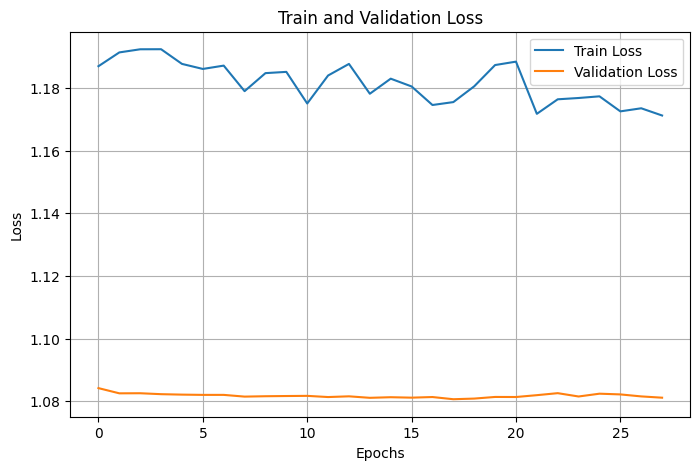

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history_c_1024.history['loss'], label='Train Loss')
plt.plot(history_c_1024.history['val_loss'], label='Validation Loss')
plt.title('Train and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
y_prob = model_classifier_1024.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
y_true = y_test
if len(y_true.shape) > 1 and y_true.shape[1] > 1:
    y_true = np.argmax(y_true, axis=1)

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


In [ ]:
# F1 score: weighted, macro
# Confusion matrix
from sklearn.metrics import f1_score, confusion_matrix, classification_report

f1 = f1_score(y_true, y_pred, average='macro')
print("F1 Score (Macro):", f1)

f1 = f1_score(y_true, y_pred, average='weighted')
print("F1 Score (Weighted):", f1)

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

F1 Score (Macro): 0.49514452145779303
F1 Score (Weighted): 0.5217111285921182
Confusion Matrix:
 [[ 65 110  11   0]
 [ 42 260 116   6]
 [  9 144 258  18]
 [  1  22  85  51]]


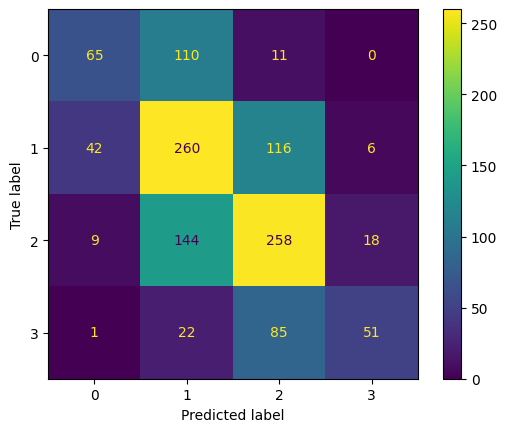

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [ ]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.56      0.35      0.43       186
           1       0.49      0.61      0.54       424
           2       0.55      0.60      0.57       429
           3       0.68      0.32      0.44       159

    accuracy                           0.53      1198
   macro avg       0.57      0.47      0.50      1198
weighted avg       0.54      0.53      0.52      1198



In [ ]:
history_c_512 = model_classifier_512.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[reduce_lr, early_stopping]
)

Epoch 1/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 66ms/step - accuracy: 0.3176 - loss: 1.6406 - val_accuracy: 0.4194 - val_loss: 1.2808 - learning_rate: 0.0010
Epoch 2/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3611 - loss: 1.4134 - val_accuracy: 0.4411 - val_loss: 1.2118 - learning_rate: 0.0010
Epoch 3/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3684 - loss: 1.3249 - val_accuracy: 0.4277 - val_loss: 1.1850 - learning_rate: 0.0010
Epoch 4/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3867 - loss: 1.2533 - val_accuracy: 0.4444 - val_loss: 1.1674 - learning_rate: 0.0010
Epoch 5/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4127 - loss: 1.2213 - val_accuracy: 0.4478 - val_loss: 1.1607 - learning_rate: 0.0010
Epoch 6/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4136 - loss: 1.2065 - val_accuracy: 0.4528 - val_loss: 1.1530 - learning_rate: 0.0010
Epoch 7/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4482 - loss: 1.1846 - val_a

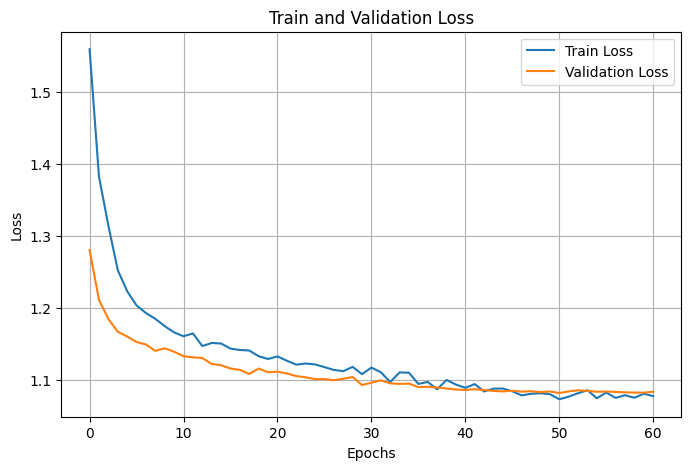

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history_c_512.history['loss'], label='Train Loss')
plt.plot(history_c_512.history['val_loss'], label='Validation Loss')
plt.title('Train and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
y_prob = model_classifier_512.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
y_true = y_test
if len(y_true.shape) > 1 and y_true.shape[1] > 1:
    y_true = np.argmax(y_true, axis=1)

38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step


In [ ]:
# F1 score: weighted, macro
# Confusion matrix

f1 = f1_score(y_true, y_pred, average='macro')
print("F1 Score (Macro):", f1)

f1 = f1_score(y_true, y_pred, average='weighted')
print("F1 Score (Weighted):", f1)

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

F1 Score (Macro): 0.4230930947617989
F1 Score (Weighted): 0.4644676928762874
Confusion Matrix:
 [[ 49 124  13   0]
 [ 32 300  90   2]
 [ 12 208 202   7]
 [  1  44  84  30]]


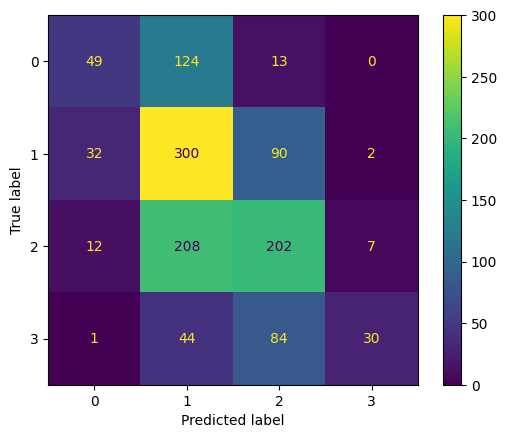

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [ ]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.52      0.26      0.35       186
           1       0.44      0.71      0.55       424
           2       0.52      0.47      0.49       429
           3       0.77      0.19      0.30       159

    accuracy                           0.48      1198
   macro avg       0.56      0.41      0.42      1198
weighted avg       0.53      0.48      0.46      1198



In [ ]:
history_c_256 = model_classifier_256.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.3655 - loss: 1.4348 - val_accuracy: 0.4378 - val_loss: 1.2055 - learning_rate: 0.0010
Epoch 2/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3660 - loss: 1.3500 - val_accuracy: 0.4394 - val_loss: 1.1786 - learning_rate: 0.0010
Epoch 3/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3878 - loss: 1.2997 - val_accuracy: 0.4528 - val_loss: 1.1621 - learning_rate: 0.0010
Epoch 4/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3980 - loss: 1.2452 - val_accuracy: 0.4461 - val_loss: 1.1532 - learning_rate: 0.0010
Epoch 5/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4106 - loss: 1.2264 - val_accuracy: 0.4353 - val_loss: 1.1524 - learning_rate: 0.0010
Epoch 6/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4430 - loss: 1.1894 - val_accuracy: 0.4461 - val_loss: 1.1462 - learning_rate: 0.0010
Epoch 7/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.4288 - loss: 1.1858 - val_

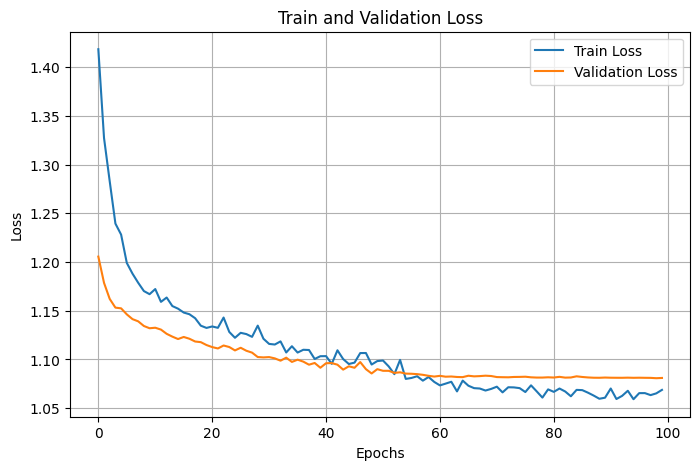

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history_c_256.history['loss'], label='Train Loss')
plt.plot(history_c_256.history['val_loss'], label='Validation Loss')
plt.title('Train and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
y_prob = model_classifier_256.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
y_true = y_test
if len(y_true.shape) > 1 and y_true.shape[1] > 1:
    y_true = np.argmax(y_true, axis=1)

38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step


In [ ]:
# F1 score: weighted, macro
# Confusion matrix

f1 = f1_score(y_true, y_pred, average='macro')
print("F1 Score (Macro):", f1)

f1 = f1_score(y_true, y_pred, average='weighted')
print("F1 Score (Weighted):", f1)

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

F1 Score (Macro): 0.4423150428974885
F1 Score (Weighted): 0.4766619863839161
Confusion Matrix:
 [[ 54 118  14   0]
 [ 37 277 107   3]
 [ 13 186 219  11]
 [  1  43  78  37]]


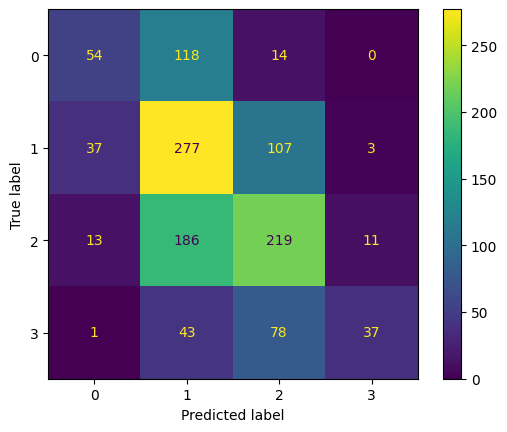

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [ ]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.51      0.29      0.37       186
           1       0.44      0.65      0.53       424
           2       0.52      0.51      0.52       429
           3       0.73      0.23      0.35       159

    accuracy                           0.49      1198
   macro avg       0.55      0.42      0.44      1198
weighted avg       0.52      0.49      0.48      1198



In [ ]:
# Regression
y = df["mos"]

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_selected, y, test_size=0.2, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42)

In [ ]:
def build_mlp_mos_regressor(input_dim):
    l2_lambda = 1e-4

    model = Sequential([
        Dense(512, kernel_regularizer=regularizers.l2(l2_lambda),
              input_shape=(input_dim,)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.3),

        Dense(256, kernel_regularizer=regularizers.l2(l2_lambda)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.3),

        Dense(128, kernel_regularizer=regularizers.l2(l2_lambda)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.3),

        Dense(64, kernel_regularizer=regularizers.l2(l2_lambda)),
        BatchNormalization(),
        Activation("relu"),
        Dropout(0.3),

        Dense(1),
        # Limit output to [1, 5]
        Lambda(lambda x: 1.0 + 4.0 * tf.nn.sigmoid(x))
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    return model

In [ ]:
model_r = build_mlp_mos_regressor(X_selected.shape[1])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
history_r = model_r.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[reduce_lr, early_stopping]
)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - loss: 1.0129 - mae: 0.7698 - val_loss: 0.5273 - val_mae: 0.5325 - learning_rate: 0.0010
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7402 - mae: 0.6481 - val_loss: 0.4887 - val_mae: 0.5114 - learning_rate: 0.0010
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6256 - mae: 0.5910 - val_loss: 0.4687 - val_mae: 0.4981 - learning_rate: 0.0010
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5763 - mae: 0.5698 - val_loss: 0.4566 - val_mae: 0.4899 - learning_rate: 0.0010
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5356 - mae: 0.5491 - val_loss: 0.4497 - val_mae: 0.4853 - learning_rate: 0.0010
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.5156 - mae: 0.5380 - val_loss: 0.4514 - val_mae: 0.4856 - learning_rate: 0.0010
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4958 - mae: 0.5255 - val_loss: 0.4527 - val_mae: 0.4909 - learning_rate: 0.00

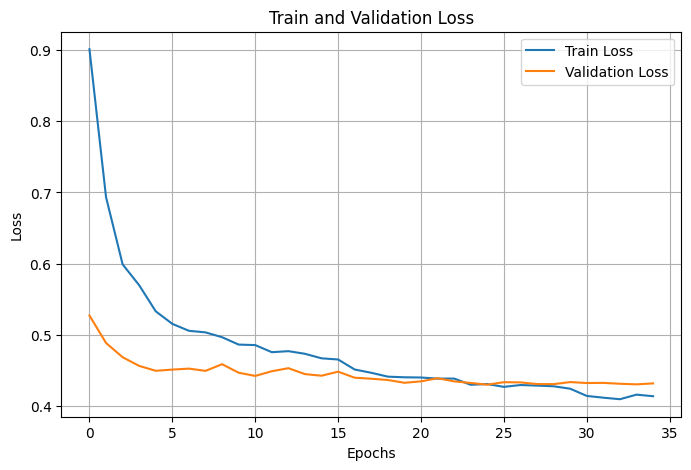

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history_r.history['loss'], label='Train Loss')
plt.plot(history_r.history['val_loss'], label='Validation Loss')
plt.title('Train and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


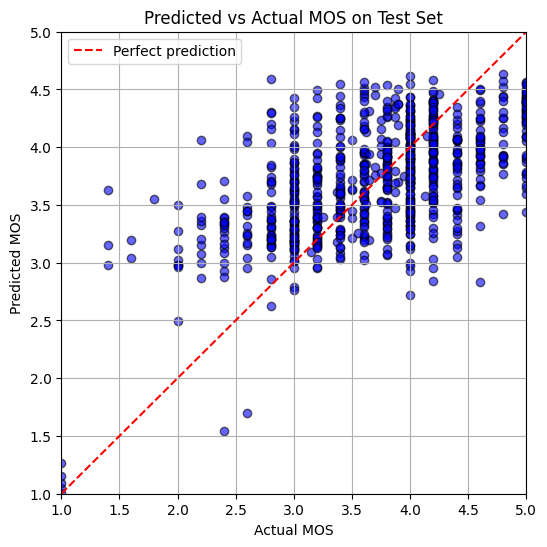

Validation MSE: 0.3677
Validation MAE: 0.4804
Validation R2: 0.3336


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


y_pred = model_r.predict(X_test).flatten()

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.6, color='blue', edgecolor='k')
plt.plot([1,5], [1,5], color='red', linestyle='--', label='Perfect prediction')
plt.xlabel("Actual MOS")
plt.ylabel("Predicted MOS")
plt.title("Predicted vs Actual MOS on Test Set")
plt.xlim(1,5)
plt.ylim(1,5)
plt.legend()
plt.grid(True)
plt.show()

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Validation MSE: {mse:.4f}")
print(f"Validation MAE: {mae:.4f}")
print(f"Validation R2: {r2:.4f}")
